In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from tensorflow.keras import Sequential, Model
from tensorflow.keras.layers import Dense, Input, Lambda

import tensorflow as tf

In [2]:
(X_test, y_test), (X_train, y_train) = mnist.load_data()

In [3]:
X_test = X_test.astype("float32") / 255.0
X_train = X_train.astype("float32") / 255.0

In [4]:
X_test = X_test.reshape(-1, 784)
X_train = X_train.reshape(-1, 784)

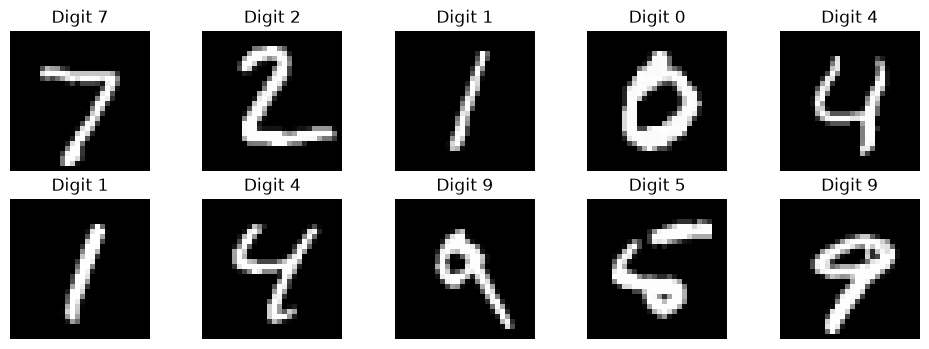

In [5]:
plt.figure(figsize=(12, 4))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(X_train[i].reshape(28,28), cmap='gray')
    plt.title(f"Digit {y_train[i]}")
    plt.axis('off')

In [6]:
encoder = Sequential([
    Input(shape=(784, )),
    Dense(256, activation="relu"),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
])

decoder = Sequential([  
    Input(shape=(64, )),
    Dense(128, activation="relu"),
    Dense(256, activation="relu"),
    Dense(784, activation="sigmoid"),
])

autoencoder = Sequential([
    encoder,
    decoder
])

autoencoder.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 64)             │       242,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 784)            │       242,832 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 484,944 (1.85 MB)

 Trainable params: 484,944 (1.85 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

history = autoencoder.fit(
    X_train, X_train,
    epochs=10,
    validation_data=(X_test, X_test),
    batch_size=32
)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.2123 - val_loss: 0.1523
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.1346 - val_loss: 0.1270
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.1167 - val_loss: 0.1144
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.1078 - val_loss: 0.1082
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.1020 - val_loss: 0.1046
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0981 - val_loss: 0.1005
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0951 - val_loss: 0.0981
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0929 - val_loss: 0.0967
Epoch 9/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0912 - val_loss: 0.0957
Epoch 10/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0898 - val_loss: 0.0943


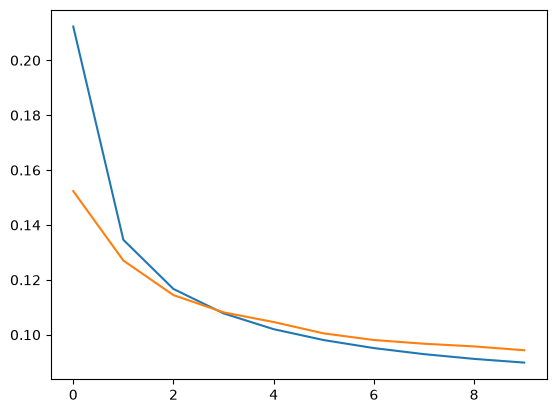

In [8]:
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])

In [9]:
reconstructed = autoencoder.predict(X_test[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step


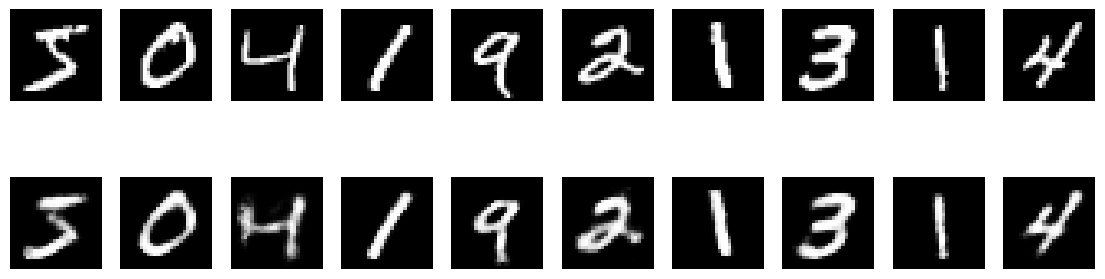

In [10]:
plt.figure(figsize=(14,4))

for i in range(10):
  plt.subplot(2, 10, i+1)
  plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
  plt.axis("off")

  plt.subplot(2, 10, i+11)
  plt.imshow(reconstructed[i].reshape(28, 28), cmap="gray")
  plt.axis("off")

In [11]:
for i in range(10):
    t = encoder.predict(X_train[i].reshape(1, 784))
    print(f"Latent vector for {y_train[i]}: \n{t}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
Latent vector for 7: 
[[7.2058744  2.8330812  3.4678798  9.387944   3.8822832  0.
  0.58355916 3.7144525  0.         0.         3.1833105  8.343823
  2.039469   1.5296377  0.         4.408609   1.7139312  5.391433
  3.688344   1.0486995  0.         0.         4.5627904  8.047668
  4.145981   6.4281     7.8834834  2.7210658  4.250389   5.0616097
  6.917733   5.716873   2.4290133  0.         6.3695965  1.6734102
  3.5741196  4.1398335  3.4924483  2.2030587  0.         0.
  2.460707   4.900243   0.         3.1647706  9.652358   8.239405
  5.8163633  0.         9.1177225  0.         0.         1.885592
  4.8733034  0.         7.28738    4.6630845  7.3372707  5.9077225
  1.417904   0.         5.214368   4.6632247 ]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
Latent vector for 2: 
[[7.4363604  0.02389298 4.8757105  2.623395   2.7943494  0.44900757
  4.817237   5.3791533  0.         0.         0.54038453 0.623695
  5.8741436  2.9305737  0.         7.2650867  4

In [12]:
(X_train, _), (X_test, _) = mnist.load_data()

X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

In [13]:
inputs = Input(shape=(784, ))
h1 = Dense(512, activation="relu")(inputs)
h2 = Dense(256, activation="relu")(h1)
h3 = Dense(128, activation="relu")(h2)

z_mean = Dense(6)(h3)
z_log_var = Dense(6)(h3)

def sampling(args):
    mean, log_var = args
    epsilon = tf.random.normal(shape=tf.shape(mean))
    return mean + tf.exp(log_var*0.5)*epsilon

z = Lambda(sampling)([z_mean, z_log_var])

encoder = Model(inputs, [z_mean, z_log_var, z])
encoder.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 784)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 512)       │    401,920 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 256)       │    131,328 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 128)       │     32,896 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 6)         │        774 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 6)         │        774 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 6)         │          0 │ dense_9[0][0],    │
│                     │                   │            │ dense_10[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 567,692 (2.17 MB)

 Trainable params: 567,692 (2.17 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
latent_input = Input(shape=(6,))
h1 = Dense(128, activation="relu")(latent_input)
h2 = Dense(256, activation="relu")(h1)
h3 = Dense(512, activation="relu")(h2)
outputs = Dense(784, activation="sigmoid")(h3)

decoder = Model(latent_input, outputs)

decoder.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 6)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 128)            │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 784)            │       402,192 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 567,696 (2.17 MB)

 Trainable params: 567,696 (2.17 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
class VAE(Model):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder 

    def train_step(self, data):

        with tf.GradientTape() as tape:
            mean, log_var, z = self.encoder(data, training=True)
            recon = self.decoder(z, training=True)

            recon_loss = tf.reduce_mean(
                tf.reduce_sum(
                    tf.keras.backend.binary_crossentropy(data, recon),
                    axis=1
                )
            )

            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + log_var - tf.square(mean) - tf.exp(log_var),
                    axis=1
                )
            )

            loss = recon_loss + kl_loss

        grads = tape.gradient(loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        return {
            "loss": loss,
            "reconstruction_loss": recon_loss,
            "kl_loss": kl_loss
        }

In [21]:
vae = VAE(encoder, decoder)
vae.compile(tf.keras.optimizers.Adam(learning_rate=0.0001))

In [22]:
vae.fit(X_train, epochs=5, batch_size=128)

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - kl_loss: 5.1634 - loss: 188.7487 - reconstruction_loss: 183.5853
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - kl_loss: 8.7047 - loss: 161.2036 - reconstruction_loss: 152.4989
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - kl_loss: 9.8742 - loss: 151.8499 - reconstruction_loss: 141.9756
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - kl_loss: 10.8724 - loss: 137.7040 - reconstruction_loss: 126.8316
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - kl_loss: 11.3712 - loss: 132.4542 - reconstruction_loss: 121.0829


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


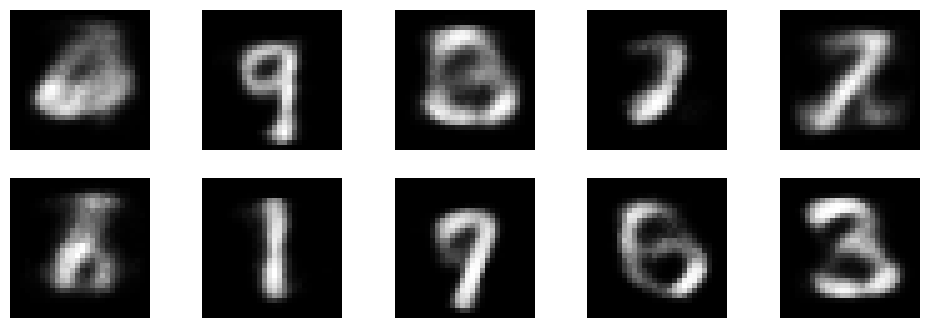

In [23]:
z_samples = np.random.normal(size=(10, 6)).astype("float32")
generated = decoder.predict(z_samples)

# 9. Display generated images
plt.figure(figsize=(12, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(generated[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

plt.show()